In [1]:
import warnings
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (precision_recall_curve, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay)

X_train, X_test, y_train, y_test = joblib.load("../data/splits.joblib")
model = joblib.load("../models/xgb_model.joblib")
proba = model.predict_proba(X_test)[:, 1]

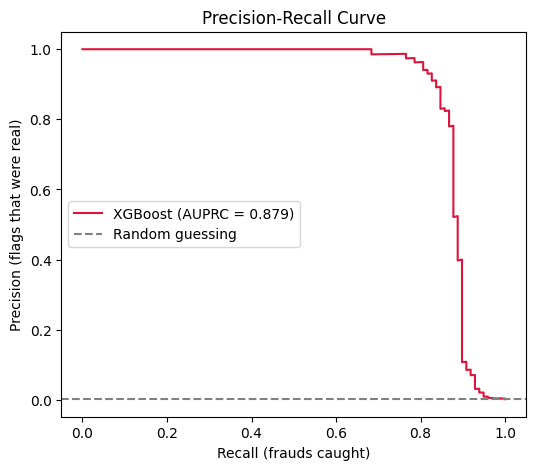

In [2]:
prec, rec, _ = precision_recall_curve(y_test, proba)
auprc = average_precision_score(y_test, proba)

plt.figure(figsize=(6, 5))
plt.plot(rec, prec, color="crimson", label=f"XGBoost (AUPRC = {auprc:.3f})")
plt.axhline(y_test.mean(), color="gray", linestyle="--", label="Random guessing")
plt.xlabel("Recall (frauds caught)")
plt.ylabel("Precision (flags that were real)")
plt.title("Precision-Recall Curve")
plt.legend()
plt.savefig("../images/pr_curve.png", dpi=150, bbox_inches="tight")
plt.show()

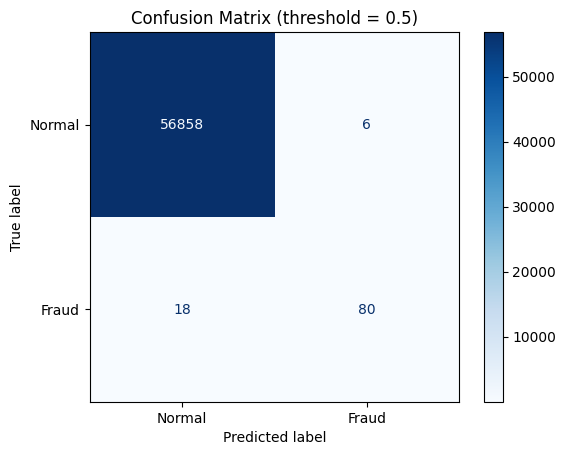

In [3]:
pred = (proba >= 0.5).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=["Normal", "Fraud"]).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix (threshold = 0.5)")
plt.savefig("../images/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
COST_MISSED_FRAUD = 5000   # ₹ lost when a fraud is missed
COST_FALSE_ALARM = 100     # ₹ cost of blocking/verifying a genuine customer

rows = []
for t in np.arange(0.05, 0.96, 0.05):
    p = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    rows.append({"Threshold": round(t, 2), "Caught": tp, "Missed": fn,
                 "False alarms": fp, "Cost": fn * COST_MISSED_FRAUD + fp * COST_FALSE_ALARM})

cost_df = pd.DataFrame(rows)
print(cost_df.to_string(index=False))

best_t = cost_df.loc[cost_df["Cost"].idxmin(), "Threshold"]
print("\nCheapest threshold:", best_t)

 Threshold  Caught  Missed  False alarms   Cost
      0.05      84      14            18  71800
      0.10      83      15            16  76600
      0.15      83      15            14  76400
      0.20      82      16            10  81000
      0.25      82      16            10  81000
      0.30      82      16            10  81000
      0.35      82      16             8  80800
      0.40      81      17             7  85700
      0.45      81      17             6  85600
      0.50      80      18             6  90600
      0.55      80      18             6  90600
      0.60      80      18             6  90600
      0.65      79      19             4  95400
      0.70      77      21             2 105200
      0.75      75      23             2 115200
      0.80      73      25             1 125100
      0.85      70      28             1 140100
      0.90      69      29             1 145100
      0.95      66      32             0 160000

Cheapest threshold: 0.05


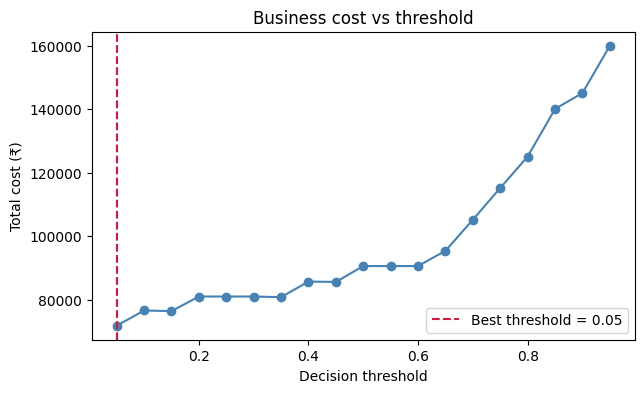

['../models/threshold.joblib']

In [5]:
plt.figure(figsize=(7, 4))
plt.plot(cost_df["Threshold"], cost_df["Cost"], marker="o", color="steelblue")
plt.axvline(best_t, color="crimson", linestyle="--", label=f"Best threshold = {best_t}")
plt.xlabel("Decision threshold")
plt.ylabel("Total cost (₹)")
plt.title("Business cost vs threshold")
plt.legend()
plt.savefig("../images/threshold_cost.png", dpi=150, bbox_inches="tight")
plt.show()

joblib.dump(float(best_t), "../models/threshold.joblib")